<center><h1>zheng_yiyi_HW4</h1></center>
<br>
<br>

Name: yiyi zheng
<br>
Github Username: yiyizheng111
<br>
USC ID: 7092417109

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline

Get the AReM Data Set

In [2]:
#Path to the AReM dataset
DATA_DIR = Path("data/ARem")
activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

# Check the activity folders
for activity in activities:
    folder = DATA_DIR / activity
    print(activity, "->", folder.exists())

bending1 -> True
bending2 -> True
cycling -> True
lying -> True
sitting -> True
standing -> True
walking -> True


### (b) Splitting Data

In [3]:
column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

def read_arem_file(file_path):
    rows = []

    with open(file_path, "r") as file:
        for line in file:
            # Skip the comment lines
            if line.startswith("#"):
                continue

            # Handle both comma-separated and space-separated files
            line = line.strip().rstrip(",")
            values = line.replace(",", " ").split()
            rows.append([float(value) for value in values])

    return pd.DataFrame(rows, columns=column_names)


train_data = []
test_data = []

for activity in activities:
    folder = DATA_DIR / activity

    files = sorted(
        folder.glob("dataset*.csv"),
        key=lambda x: int(x.stem.replace("dataset", ""))
    )

    for file_path in files:
        dataset_number = int(file_path.stem.replace("dataset", ""))

        data = read_arem_file(file_path)

        instance = {
            "activity": activity,
            "dataset": dataset_number,
            "data": data
        }

        if activity in ["bending1", "bending2"]:
            if dataset_number in [1, 2]:
                test_data.append(instance)
            else:
                train_data.append(instance)
        else:
            if dataset_number in [1, 2, 3]:
                test_data.append(instance)
            else:
                train_data.append(instance)

print("Number of training instances:", len(train_data))
print("Number of testing instances:", len(test_data))
print("Total number of instances:", len(train_data) + len(test_data))

Number of training instances: 69
Number of testing instances: 19
Total number of instances: 88


### (c) Feature Extraction

In [4]:
time_series_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

feature_rows = []

all_data = [
    ("train", instance) for instance in train_data
] + [
    ("test", instance) for instance in test_data
]

for i, (split, instance) in enumerate(all_data, start=1):
    data = instance["data"]

    row = {
        "Instance": i,
        "activity": instance["activity"],
        "dataset": instance["dataset"],
        "split": split
    }

    for j, column in enumerate(time_series_columns, start=1):
        series = data[column]

        row[f"min{j}"] = series.min()
        row[f"max{j}"] = series.max()
        row[f"mean{j}"] = series.mean()
        row[f"median{j}"] = series.median()
        row[f"std{j}"] = series.std()
        row[f"1st_quart{j}"] = series.quantile(0.25)
        row[f"3rd_quart{j}"] = series.quantile(0.75)

    feature_rows.append(row)

feature_df = pd.DataFrame(feature_rows)

feature_columns = [
    column for column in feature_df.columns
    if column not in ["Instance", "activity", "dataset", "split"]
]

print("Number of instances:", len(feature_df))
print("Number of extracted features:", len(feature_columns))
print("Shape of feature dataset:", feature_df.shape)

feature_df.head()

Number of instances: 88
Number of extracted features: 42
Shape of feature dataset: (88, 46)


,Instance,activity,dataset,split,min1,max1,mean1,median1,std1,1st_quart1,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,1,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94
1,2,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
2,3,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
3,4,bending1,6,train,37.00,48.00,43.454958,43.25,1.386098,42.50,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
4,5,bending1,7,train,36.25,48.00,43.969125,44.50,1.618364,43.31,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

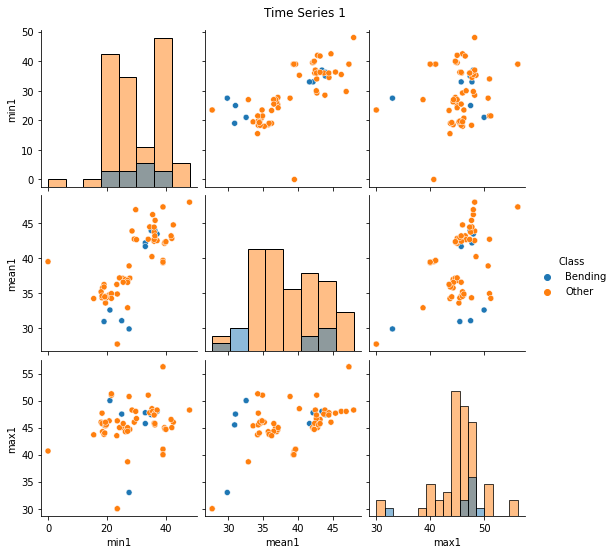

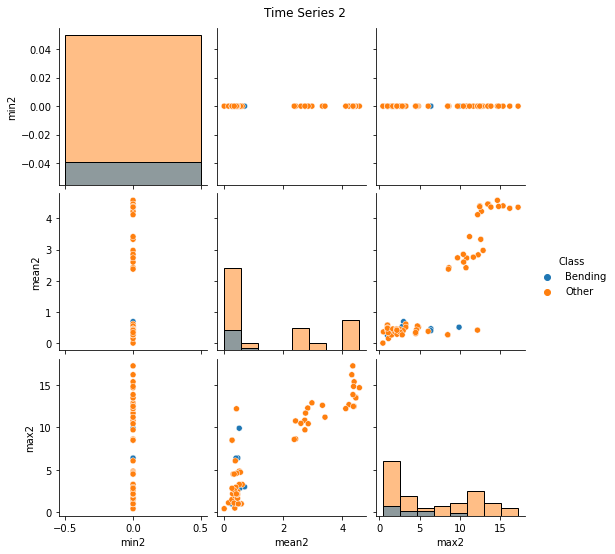

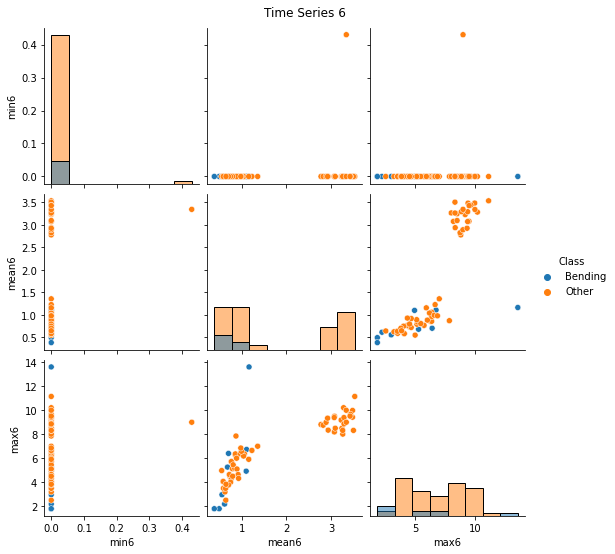

In [6]:

# Use only the training data
train_features = feature_df[feature_df["split"] == "train"].copy()

# Binary classification: bending vs other activities
train_features["Class"] = train_features["activity"].apply(
    lambda x: "Bending" if x in ["bending1", "bending2"] else "Other"
)

# Plot features from time series 1, 2, and 6
for i in [1, 2, 6]:
    selected_features = [
        f"min{i}",
        f"mean{i}",
        f"max{i}"
    ]

    g = sns.pairplot(
        train_features,
        vars=selected_features,
        hue="Class",
        diag_kind="hist",
        height=2.5
    )

    g.fig.suptitle(f"Time Series {i}", y=1.02)
    plt.show()


For time series 1, the two classes overlap a lot, so it is difficult to separate them using these features.

In time series 2, the minimum value is always zero, so it is not useful for classification. But, the mean and maximum values show some differences between the two classes.

Time series 6 bending activities generally have lower mean values, while some other activities have much higher values.

These features can help distinguish the two classes, but they cannot completely separate them.

#### ii. Splitted Plots

Number of training instances: 69


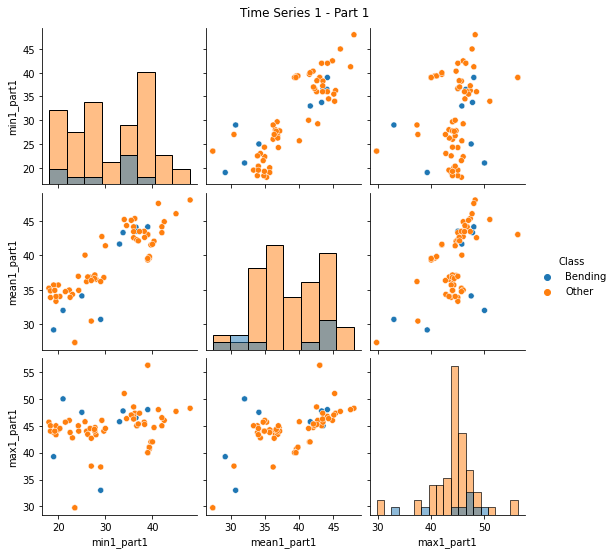

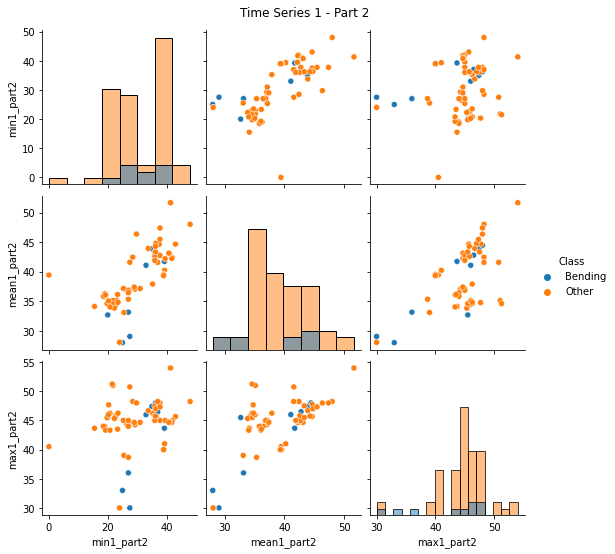

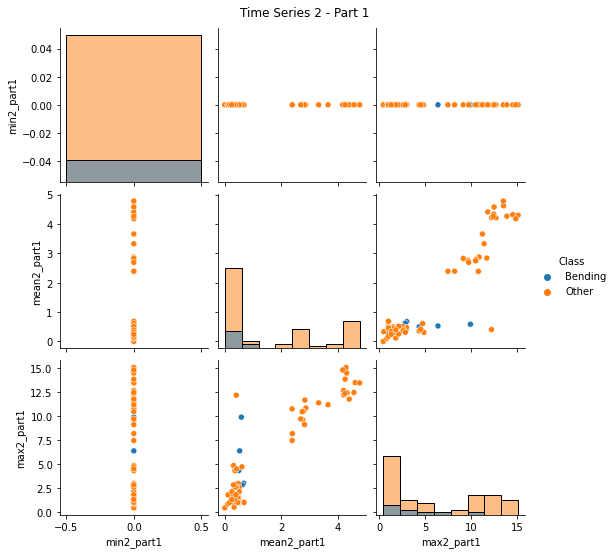

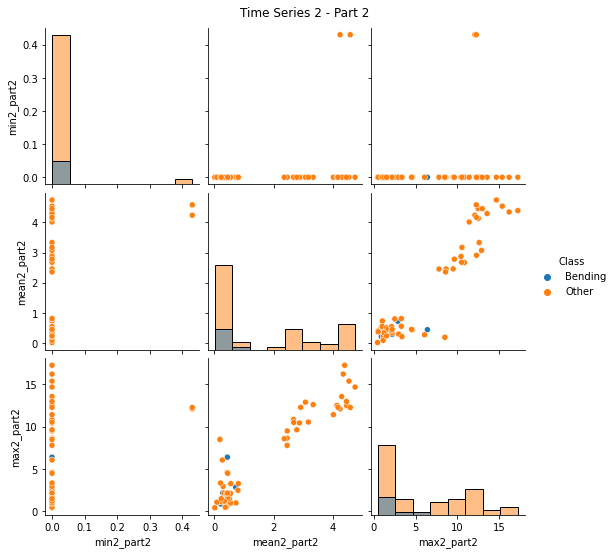

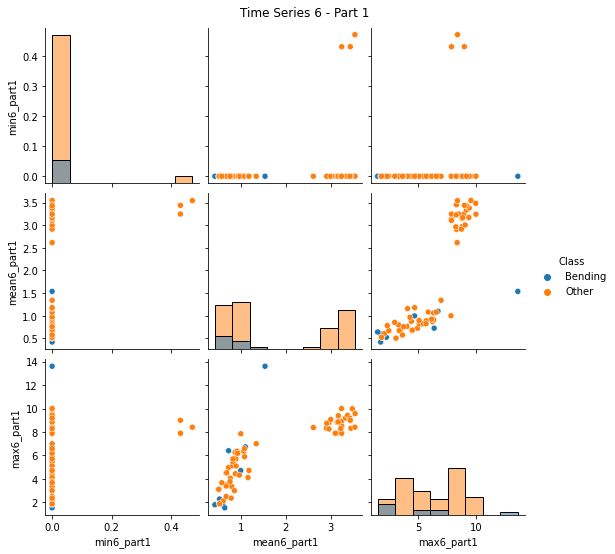

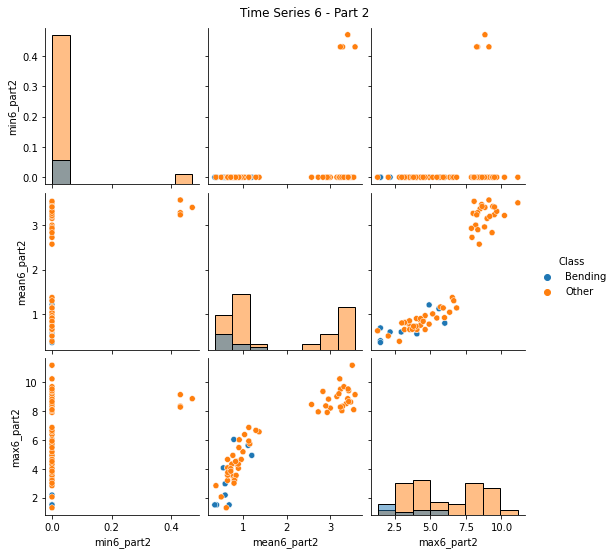

In [7]:

# Split each time series into two parts
split_rows = []

for instance in train_data:
    data = instance["data"]
    midpoint = len(data) // 2

    parts = [
        data.iloc[:midpoint],
        data.iloc[midpoint:]
    ]

    row = {
        "activity": instance["activity"],
        "Class": "Bending" if instance["activity"] in ["bending1", "bending2"] else "Other"
    }

    for part_num, part in enumerate(parts, start=1):
        for i in [1, 2, 6]:
            series = part[time_series_columns[i - 1]]

            row[f"min{i}_part{part_num}"] = series.min()
            row[f"mean{i}_part{part_num}"] = series.mean()
            row[f"max{i}_part{part_num}"] = series.max()

    split_rows.append(row)

split_features_df = pd.DataFrame(split_rows)

print("Number of training instances:", len(split_features_df))

# Scatter plots for both parts
for i in [1, 2, 6]:
    for part_num in [1, 2]:
        selected_features = [
            f"min{i}_part{part_num}",
            f"mean{i}_part{part_num}",
            f"max{i}_part{part_num}"
        ]

        g = sns.pairplot(
            split_features_df,
            vars=selected_features,
            hue="Class",
            diag_kind="hist",
            height=2.5
        )

        g.fig.suptitle(
            f"Time Series {i} - Part {part_num}",
            y=1.02
        )

        plt.show()


After splitting the time series into two parts, the scatter plots show some small changes.

In time series 1, bending and other activities still overlap a lot in both parts.

For time series 2, the mean and maximum values show some differences, but the two classes still have overlap.

Some other activities have much higher mean values in time series 6. However, bending and other activities are still mixed in the lower-value area.

Overall, I do not see a considerable difference compared with the original plots. Splitting the time series into two parts does not clearly improve the separation of two classes.

#### iii. Time Series Segments

In [9]:

# Extract features after splitting each time series into l segments

def extract_segment_features(instances, l):
    rows = []

    for instance in instances:
        data = instance["data"]
        row = {}

        for i, column in enumerate(time_series_columns, start=1):
            segments = np.array_split(data[column].to_numpy(), l)

            for j, segment in enumerate(segments, start=1):
                row[f"min{i}_seg{j}"] = np.min(segment)
                row[f"max{i}_seg{j}"] = np.max(segment)
                row[f"mean{i}_seg{j}"] = np.mean(segment)
                row[f"median{i}_seg{j}"] = np.median(segment)
                row[f"std{i}_seg{j}"] = np.std(segment, ddof=1)
                row[f"1st_quart{i}_seg{j}"] = np.quantile(segment, 0.25)
                row[f"3rd_quart{i}_seg{j}"] = np.quantile(segment, 0.75)

        rows.append(row)

    return pd.DataFrame(rows)


# Binary labels: bending = 1, other activities = 0
y_train = np.array([
    1 if instance["activity"] in ["bending1", "bending2"] else 0
    for instance in train_data
])

print("Training class counts:")
print("Bending:", sum(y_train == 1))
print("Other:", sum(y_train == 0))

# Check the number of features for different l values
for l in [1, 2, 20]:
    X_train = extract_segment_features(train_data, l)

    print(f"\nl = {l}")
    print("Shape:", X_train.shape)
    print("Number of features:", X_train.shape[1])


Training class counts:
Bending: 9
Other: 60

l = 1
Shape: (69, 42)
Number of features: 42

l = 2
Shape: (69, 84)
Number of features: 84

l = 20
Shape: (69, 840)
Number of features: 840


In [11]:

# Test Logistic Regression with l = 1 and p = 10

l = 1
p = 10

X_train = extract_segment_features(train_data, l)

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic regression with very small regularization
log_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=500
)

# Standardization, RFE and logistic regression
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=log_model,
        n_features_to_select=p,
        step=0.5
    )),
    ("model", log_model)
])

# Cross-validation
cv_scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("l =", l)
print("p =", p)
print("CV accuracy scores:", cv_scores)
print("Mean CV accuracy:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())


l = 1
p = 10
CV accuracy scores: [1.         0.92857143 0.92857143 1.         1.        ]
Mean CV accuracy: 0.9714285714285715
Standard deviation: 0.03499271061118824


In [12]:

# Find the best l and p using 5-fold cross-validation

p_values = [5, 10, 20, 40]
cv_results = []

for l in range(1, 21):

    X_l = extract_segment_features(train_data, l)

    for p in p_values:

        log_model = LogisticRegression(
            C=1e6,
            solver="liblinear",
            max_iter=500
        )

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("rfe", RFE(
                estimator=log_model,
                n_features_to_select=p,
                step=0.5
            )),
            ("model", log_model)
        ])

        scores = cross_val_score(
            pipeline,
            X_l,
            y_train,
            cv=cv,
            scoring="accuracy"
        )

        cv_results.append({
            "l": l,
            "p": p,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    print(f"Finished l = {l}")


# Sort by CV accuracy
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by=["Mean CV Accuracy", "l", "p"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("\nTop 10 combinations:")
print(cv_results_df.head(10).round(4).to_string(index=False))

best_result = cv_results_df.iloc[0]

print("\nBest combination from this search:")
print("Best l:", int(best_result["l"]))
print("Best p:", int(best_result["p"]))
print("Best CV Accuracy:", round(best_result["Mean CV Accuracy"], 4))


Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20

Top 10 combinations:
 l  p  Mean CV Accuracy  CV Std
 1 10            0.9714  0.0350
 1 20            0.9714  0.0350
 1 40            0.9714  0.0350
18 40            0.9714  0.0350
 1  5            0.9571  0.0571
17 40            0.9571  0.0571
19 40            0.9571  0.0571
17 10            0.9560  0.0359
 4 20            0.9429  0.0535
 6 10            0.9429  0.0833

Best combination from this search:
Best l: 1
Best p: 10
Best CV Accuracy: 0.9714


In [13]:

# Find the best number of features when l = 1

X_l1 = extract_segment_features(train_data, 1)

refined_results = []

for p in range(1, 43):

    log_model = LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=500
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(
            estimator=log_model,
            n_features_to_select=p,
            step=0.5
        )),
        ("model", log_model)
    ])

    scores = cross_val_score(
        pipeline,
        X_l1,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    refined_results.append({
        "p": p,
        "Mean CV Accuracy": scores.mean(),
        "CV Std": scores.std()
    })


refined_df = pd.DataFrame(refined_results)

refined_df = refined_df.sort_values(
    by=["Mean CV Accuracy", "p"],
    ascending=[False, True]
).reset_index(drop=True)

print("Top 10 results:")
print(refined_df.head(10).round(4).to_string(index=False))

best_accuracy = refined_df["Mean CV Accuracy"].max()

best_p_values = refined_df.loc[
    np.isclose(refined_df["Mean CV Accuracy"], best_accuracy),
    "p"
].tolist()

print("\nHighest CV Accuracy:", round(best_accuracy, 4))
print("p values with highest accuracy:", best_p_values)
print("Smallest p with highest accuracy:", min(best_p_values))


Top 10 results:
 p  Mean CV Accuracy  CV Std
 6            0.9714  0.0571
 8            0.9714  0.0350
 9            0.9714  0.0350
10            0.9714  0.0350
11            0.9714  0.0350
12            0.9714  0.0350
13            0.9714  0.0350
15            0.9714  0.0350
16            0.9714  0.0350
17            0.9714  0.0350

Highest CV Accuracy: 0.9714
p values with highest accuracy: [6, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 34, 35, 36, 37, 39, 40, 41, 42]
Smallest p with highest accuracy: 6


I used stratified 5-fold cross-validation to select l and p. The bending class has 9 training instances. Stratified cross-validation can help keep the class proportion in each fold.

From the combinations I tested, the highest mean CV accuracy was 97.14%. When l = 1, several p values had the same accuracy. I chose p = 6 because it uses fewer features.

The right way is to do standardization and feature selection inside each training fold, and then evaluate the model on the validation fold.

The wrong way is to select features using the whole dataset before cross-validation. This would use information from the validation data and may give a higher accuracy than the actual performance.

#### iv. Confusion Matrix

Selected features:
['min1_seg1', '3rd_quart1_seg1', 'max2_seg1', 'max4_seg1', 'min5_seg1', 'max5_seg1']

Confusion Matrix:
[[60  0]
 [ 0  9]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69

Training AUC: 1.0

Logistic Regression Coefficients:
        Feature  Coefficient
      min1_seg1      -6.6031
3rd_quart1_seg1      -4.5226
      max2_seg1     -10.0296
      max4_seg1      -0.0555
      min5_seg1      10.1087
      max5_seg1      13.2768


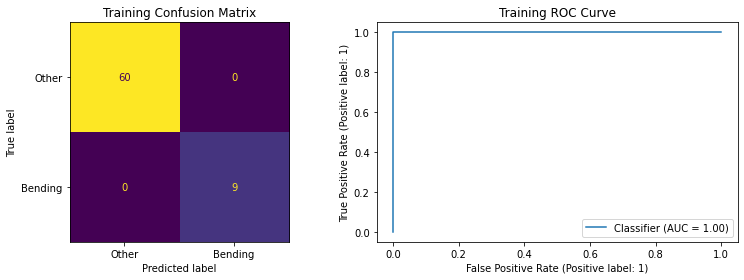

In [14]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Selected parameters
best_l = 1
best_p = 6

X_train_best = extract_segment_features(train_data, best_l)

log_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=500
)

best_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=log_model,
        n_features_to_select=best_p,
        step=0.5
    )),
    ("model", log_model)
])

# Fit on the training data
best_pipeline.fit(X_train_best, y_train)

# Selected features
selected_features = X_train_best.columns[
    best_pipeline.named_steps["rfe"].support_
]

print("Selected features:")
print(selected_features.tolist())

# Training predictions
y_pred_train = best_pipeline.predict(X_train_best)
y_prob_train = best_pipeline.predict_proba(X_train_best)[:, 1]

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, y_pred_train))

print("\nClassification Report:")
print(classification_report(y_train, y_pred_train))

print("Training AUC:", roc_auc_score(y_train, y_prob_train))

# Logistic regression coefficients
coef_df = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": best_pipeline.named_steps["model"].coef_[0]
})

print("\nLogistic Regression Coefficients:")
print(coef_df.round(4).to_string(index=False))

# Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_pred_train,
    display_labels=["Other", "Bending"],
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Training Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_train,
    y_prob_train,
    pos_label=1,
    ax=axes[1]
)

axes[1].set_title("Training ROC Curve")

plt.tight_layout()
plt.show()


In [15]:

import statsmodels.api as sm
import warnings

# Use the six selected features
X_scaled = best_pipeline.named_steps["scaler"].transform(X_train_best)
X_selected = best_pipeline.named_steps["rfe"].transform(X_scaled)

X_sm = pd.DataFrame(
    X_selected,
    columns=selected_features.tolist()
)

# Add intercept
X_sm = sm.add_constant(X_sm)

print("Sklearn intercept:")
print(best_pipeline.named_steps["model"].intercept_[0])

# Fit logistic regression using statsmodels
with warnings.catch_warnings(record=True) as warning_list:
    warnings.simplefilter("always")

    try:
        sm_model = sm.Logit(y_train, X_sm)
        sm_result = sm_model.fit(disp=False, maxiter=200)

        pvalue_df = pd.DataFrame({
            "Coefficient": sm_result.params,
            "P-value": sm_result.pvalues
        })

        print("\nConverged:", sm_result.mle_retvals["converged"])
        print("\nCoefficients and P-values:")
        print(pvalue_df.round(4))

    except Exception as e:
        print("\nModel fitting problem:")
        print(type(e).__name__, ":", str(e))

    for warning in warning_list:
        print("\nWarning:", str(warning.message))


/opt/anaconda3/lib/python3.8/site-packages/statsmodels/tsa/base/tsa_model.py:7: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import (to_datetime, Int64Index, DatetimeIndex, Period,
/opt/anaconda3/lib/python3.8/site-packages/statsmodels/tsa/base/tsa_model.py:7: FutureWarning: pandas.Float64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import (to_datetime, Int64Index, DatetimeIndex, Period,


Sklearn intercept:
-21.881277533522315

Model fitting problem:
LinAlgError : Singular matrix







































































































































































































































































































































































































































































































































/opt/anaconda3/lib/python3.8/site-packages/statsmodels/tsa/tsatools.py:142: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  x = pd.concat(x[::order], 1)


All 69 training instances were classified correctly, including 60 other activities and 9 bending activities.

The training accuracy was 100%, and the AUC was 1.00. However, the mean CV accuracy was 97.14%, so the model may not perform perfectly on new data.

I also calculated the coefficients for the 6 selected features. But when I tried to calculate the p-values using statsmodels, I got a singular matrix error.

This may be caused by complete separation because the model can separate the two classes perfectly in the training data. Therefore, I could not get reliable p-values for this model.

#### v. Test Classifier

Number of test instances: 19
Test Accuracy: 1.0
Test Error: 0.0
Test AUC: 1.0

Test Confusion Matrix:
[[15  0]
 [ 0  4]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       1.00      1.00      1.00         4

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19



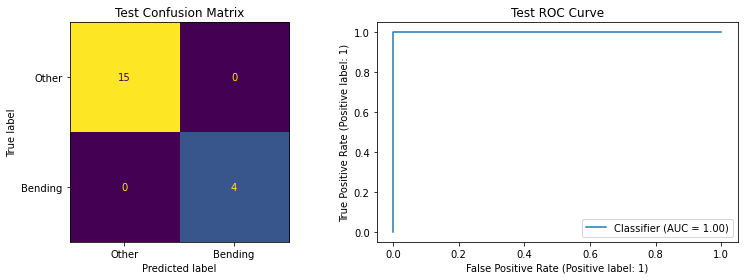

In [16]:

# Prepare the test data using the selected l

X_test = extract_segment_features(test_data, best_l)

y_test = np.array([
    1 if instance["activity"] in ["bending1", "bending2"] else 0
    for instance in test_data
])

# Use the trained model to predict the test data
y_pred_test = best_pipeline.predict(X_test)
y_prob_test = best_pipeline.predict_proba(X_test)[:, 1]

# Test results
test_accuracy = (y_pred_test == y_test).mean()
test_error = 1 - test_accuracy
test_auc = roc_auc_score(y_test, y_prob_test)

print("Number of test instances:", len(y_test))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Error:", round(test_error, 4))
print("Test AUC:", round(test_auc, 4))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test))

# Test confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=["Other", "Bending"],
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Test Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_test,
    pos_label=1,
    ax=axes[1]
)

axes[1].set_title("Test ROC Curve")

plt.tight_layout()
plt.show()


I used the selected logistic regression model to predict the test data.

All 19 test instances were classified correctly, including 15 other activities and 4 bending activities.

The test accuracy was 100%, the test error was 0%, and the AUC was 1.00.

The model performed very well on the test data. However, the test set is small, so we cannot be sure it will always have the same performance on new data.

#### vi. Separation

Yes, the two classes seem to be well-separated in the training data.

The training accuracy was 100%, and the AUC was 1.00. All 69 training instances were classified correctly.

When I used statsmodels to calculate the p-values, I got a singular matrix error and overflow warnings. This may be caused by complete separation, and makes the logistic regression parameters unstable.

Using regularization can help with this problem.

#### vii. Imbalance

Case-control sample:
Bending: 9
Other: 9

Intercept adjustment: -1.8971
Adjusted intercept: -1.7293

Training Confusion Matrix:
[[60  0]
 [ 5  4]]

Training Accuracy: 0.9275
Training AUC: 1.0


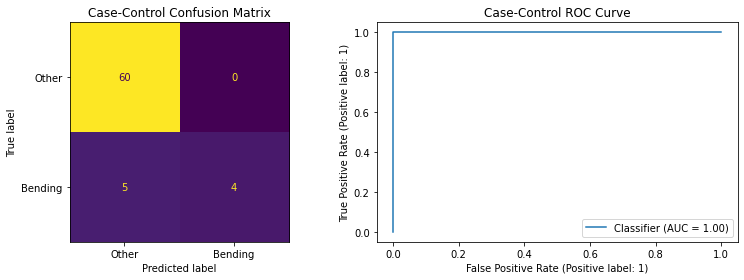

In [18]:

from scipy.special import expit

# Case-control sampling
rng = np.random.RandomState(42)

bending_idx = np.where(y_train == 1)[0]
other_idx = np.where(y_train == 0)[0]

sampled_other_idx = rng.choice(
    other_idx,
    size=len(bending_idx),
    replace=False
)

sample_idx = np.concatenate([bending_idx, sampled_other_idx])

# Use the 6 selected features
X_cc = X_train_best.iloc[sample_idx][selected_features]
y_cc = y_train[sample_idx]

print("Case-control sample:")
print("Bending:", sum(y_cc == 1))
print("Other:", sum(y_cc == 0))

# Fit logistic regression on balanced data
cc_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=1000
    ))
])

cc_model.fit(X_cc, y_cc)

# Adjust intercept for original class proportions
original_odds = sum(y_train == 1) / sum(y_train == 0)
sample_odds = sum(y_cc == 1) / sum(y_cc == 0)

adjustment = np.log(original_odds) - np.log(sample_odds)

cc_model.named_steps["model"].intercept_[0] += adjustment

print("\nIntercept adjustment:", round(adjustment, 4))
print("Adjusted intercept:",
      round(cc_model.named_steps["model"].intercept_[0], 4))

# Evaluate on the full training set
X_full = X_train_best[selected_features]

y_cc_pred = cc_model.predict(X_full)
y_cc_prob = cc_model.predict_proba(X_full)[:, 1]

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train, y_cc_pred))

print("\nTraining Accuracy:", round(
    (y_cc_pred == y_train).mean(), 4
))

print("Training AUC:", round(
    roc_auc_score(y_train, y_cc_prob), 4
))

# Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_cc_pred,
    display_labels=["Other", "Bending"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Case-Control Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_train,
    y_cc_prob,
    pos_label=1,
    ax=axes[1]
)
axes[1].set_title("Case-Control ROC Curve")

plt.tight_layout()
plt.show()


The training data is imbalanced. There are 9 bending instances.

I used case-control sampling to select 9 bending instances. Then I adjusted the intercept based on the original class proportions.

The confusion matrix shows that all 60 other activities were classified correctly, but 5 bending activities were classified as other activities.

The training accuracy was 92.75%, and the AUC was 1.00.

Although the AUC was 1.00, the accuracy was lower than the previous model. This is because AUC measures how well the model ranks the two classes, while accuracy depends on the classification threshold.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [19]:

# L1-penalized Logistic Regression with 5-fold CV

C_values = [0.01, 0.1, 1, 10, 100]
l1_results = []

for l in range(1, 21):

    X_l = extract_segment_features(train_data, l)

    for C in C_values:

        l1_pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                penalty="l1",
                C=C,
                solver="liblinear",
                max_iter=2000,
                random_state=42
            ))
        ])

        scores = cross_val_score(
            l1_pipeline,
            X_l,
            y_train,
            cv=cv,
            scoring="accuracy"
        )

        l1_results.append({
            "l": l,
            "C": C,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    print(f"Finished l = {l}")


# Sort the results
l1_results_df = pd.DataFrame(l1_results)

l1_results_df = l1_results_df.sort_values(
    by=["Mean CV Accuracy", "l", "C"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("\nTop 10 combinations:")
print(l1_results_df.head(10).round(4).to_string(index=False))

best_l1 = l1_results_df.iloc[0]

print("\nBest L1 combination from this search:")
print("Best l:", int(best_l1["l"]))
print("Best C:", best_l1["C"])
print("Best CV Accuracy:", round(best_l1["Mean CV Accuracy"], 4))


Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20

Top 10 combinations:
 l     C  Mean CV Accuracy  CV Std
19   1.0            0.9857  0.0286
10 100.0            0.9714  0.0350
11   1.0            0.9714  0.0350
11  10.0            0.9714  0.0350
12   1.0            0.9714  0.0350
12  10.0            0.9714  0.0350
12 100.0            0.9714  0.0350
13   1.0            0.9714  0.0350
14   1.0            0.9714  0.0350
18   1.0            0.9714  0.0350

Best L1 combination from this search:
Best l: 19
Best C: 1.0
Best CV Accuracy: 0.9857


Best l: 19
Best C: 1.0
Total features: 798
Selected features: 10

Top 15 selected features:
        Feature  Coefficient  Abs Coefficient
1st_quart5_seg3       2.1184           2.1184
     min5_seg17       0.6198           0.6198
     max1_seg11      -0.5713           0.5713
     std6_seg15      -0.2157           0.2157
     max6_seg18      -0.1195           0.1195
     std5_seg18      -0.0741           0.0741
      min5_seg2       0.0630           0.0630
     std4_seg14      -0.0517           0.0517
      min5_seg3       0.0285           0.0285
      max5_seg5       0.0108           0.0108

Training Accuracy: 1.0
Test Accuracy: 0.9474
Test Error: 0.0526
Test AUC: 0.9833

Test Confusion Matrix:
[[15  0]
 [ 1  3]]


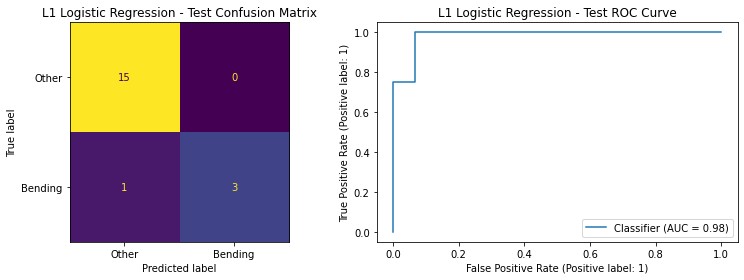

In [20]:

# Fit the best L1 logistic regression model

best_l1_l = int(best_l1["l"])
best_l1_C = float(best_l1["C"])

X_train_l1 = extract_segment_features(train_data, best_l1_l)
X_test_l1 = extract_segment_features(test_data, best_l1_l)

l1_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l1",
        C=best_l1_C,
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ))
])

l1_model.fit(X_train_l1, y_train)

# Check the selected features
coefficients = l1_model.named_steps["model"].coef_[0]

selected_mask = np.abs(coefficients) > 1e-6

selected_l1_features = X_train_l1.columns[selected_mask]

print("Best l:", best_l1_l)
print("Best C:", best_l1_C)
print("Total features:", X_train_l1.shape[1])
print("Selected features:", len(selected_l1_features))

# Show the most important nonzero coefficients
l1_coef_df = pd.DataFrame({
    "Feature": X_train_l1.columns,
    "Coefficient": coefficients
})

l1_coef_df = l1_coef_df[selected_mask].copy()
l1_coef_df["Abs Coefficient"] = l1_coef_df["Coefficient"].abs()

l1_coef_df = l1_coef_df.sort_values(
    "Abs Coefficient", ascending=False
)

print("\nTop 15 selected features:")
print(l1_coef_df.head(15).round(4).to_string(index=False))

# Training and test predictions
y_pred_train_l1 = l1_model.predict(X_train_l1)
y_pred_test_l1 = l1_model.predict(X_test_l1)
y_prob_test_l1 = l1_model.predict_proba(X_test_l1)[:, 1]

print("\nTraining Accuracy:",
      round((y_pred_train_l1 == y_train).mean(), 4))

print("Test Accuracy:",
      round((y_pred_test_l1 == y_test).mean(), 4))

print("Test Error:",
      round((y_pred_test_l1 != y_test).mean(), 4))

print("Test AUC:",
      round(roc_auc_score(y_test, y_prob_test_l1), 4))

print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test_l1))

# Test confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test_l1,
    display_labels=["Other", "Bending"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("L1 Logistic Regression - Test Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_test_l1,
    pos_label=1,
    ax=axes[1]
)
axes[1].set_title("L1 Logistic Regression - Test ROC Curve")

plt.tight_layout()
plt.show()


I used L1-penalized logistic regression with stratified 5-fold cross-validation to select l and C.

The best l was 19, and the best C was 1.0. 
The mean CV accuracy was 98.57%.

There were 798 features before feature selection, and L1 regularization selected 10 features.

The training accuracy was 100%. 
The test accuracy was 94.74%.
The test error was 5.26%. 
The test AUC was 0.9833.

From the confusion matrix, 18 out of 19 test instances were classified correctly. One bending activity was incorrectly classified as another activity.

#### ii. Comparison

The L1 model had a higher CV accuracy (98.57%) than the RFE model (97.14%).

However, the RFE model had a higher test accuracy. 
RFE reached 100%, while L1 reached 94.74%.

For this test set, RFE performed better. But L1 was easier to implement because it can select features automatically by setting some coefficients to zero.

In the previous method, I used RFE instead of p-values for feature selection.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [21]:

# Prepare labels for multiclass classification

y_train_multi = np.array([
    instance["activity"] for instance in train_data
])

y_test_multi = np.array([
    instance["activity"] for instance in test_data
])

print("Training class counts:")
print(pd.Series(y_train_multi).value_counts().reindex(activities))

print("\nTest class counts:")
print(pd.Series(y_test_multi).value_counts().reindex(activities))

print("\nNumber of classes:", len(np.unique(y_train_multi)))

# Use 4-fold CV because the smallest training class has 4 instances
cv_multi = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

print("Number of CV folds:", cv_multi.n_splits)


Training class counts:
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
dtype: int64

Test class counts:
bending1    2
bending2    2
cycling     3
lying       3
sitting     3
standing    3
walking     3
dtype: int64

Number of classes: 7
Number of CV folds: 4


In [22]:

# L1-penalized multinomial logistic regression

C_values_multi = [0.01, 0.1, 1, 10]
multi_results = []

for l in range(1, 21):

    X_l = extract_segment_features(train_data, l)

    for C in C_values_multi:

        multi_pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                penalty="l1",
                C=C,
                solver="saga",
                multi_class="multinomial",
                max_iter=3000,
                tol=1e-3,
                random_state=42
            ))
        ])

        scores = cross_val_score(
            multi_pipeline,
            X_l,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy"
        )

        multi_results.append({
            "l": l,
            "C": C,
            "Mean CV Accuracy": scores.mean(),
            "CV Std": scores.std()
        })

    print(f"Finished l = {l}")


# Sort the results
multi_results_df = pd.DataFrame(multi_results)

multi_results_df = multi_results_df.sort_values(
    by=["Mean CV Accuracy", "l", "C"],
    ascending=[False, True, True]
).reset_index(drop=True)

print("\nTop 10 combinations:")
print(multi_results_df.head(10).round(4).to_string(index=False))

best_multi = multi_results_df.iloc[0]

print("\nBest Multinomial Logistic Regression:")
print("Best l:", int(best_multi["l"]))
print("Best C:", best_multi["C"])
print("Best CV Accuracy:", round(best_multi["Mean CV Accuracy"], 4))


Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20

Top 10 combinations:
 l    C  Mean CV Accuracy  CV Std
 1  1.0            0.9142  0.0625
 1 10.0            0.8840  0.0832
 9  1.0            0.8701  0.0751
 2  1.0            0.8701  0.0467
 5 10.0            0.8693  0.0645
 9 10.0            0.8554  0.0969
 4 10.0            0.8546  0.0888
15  1.0            0.8546  0.0981
 2 10.0            0.8538  0.0669
17  1.0            0.8407  0.0637

Best Multinomial Logistic Regression:
Best l: 1
Best C: 1.0
Best CV Accuracy: 0.9142


Best l: 1
Best C: 1.0
CV Accuracy: 0.9142
Training Accuracy: 0.9855
Test Accuracy: 0.8947
Test Error: 0.1053
Macro AUC: 0.994

Test Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]

Classification Report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.67      0.67      0.67         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.90      0.90      0.90        19
weighted avg       0.89      0.89      0.89        19



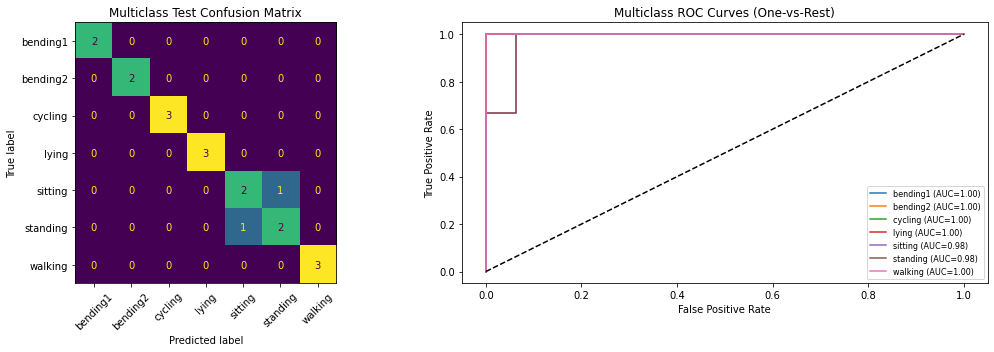

In [23]:

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Best parameters from cross-validation
best_multi_l = int(best_multi["l"])
best_multi_C = float(best_multi["C"])

# Extract training and test features
X_train_multi = extract_segment_features(train_data, best_multi_l)
X_test_multi = extract_segment_features(test_data, best_multi_l)

# Train the multinomial logistic regression model
multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l1",
        C=best_multi_C,
        solver="saga",
        multi_class="multinomial",
        max_iter=3000,
        tol=1e-3,
        random_state=42
    ))
])

multi_model.fit(X_train_multi, y_train_multi)

# Predictions
y_train_pred_multi = multi_model.predict(X_train_multi)
y_test_pred_multi = multi_model.predict(X_test_multi)
y_test_prob_multi = multi_model.predict_proba(X_test_multi)

# Accuracy and error
train_accuracy_multi = (
    y_train_pred_multi == y_train_multi
).mean()

test_accuracy_multi = (
    y_test_pred_multi == y_test_multi
).mean()

test_error_multi = 1 - test_accuracy_multi

# Multiclass AUC
class_names = multi_model.named_steps["model"].classes_

macro_auc_multi = roc_auc_score(
    y_test_multi,
    y_test_prob_multi,
    labels=class_names,
    multi_class="ovr",
    average="macro"
)

print("Best l:", best_multi_l)
print("Best C:", best_multi_C)
print("CV Accuracy:", round(best_multi["Mean CV Accuracy"], 4))
print("Training Accuracy:", round(train_accuracy_multi, 4))
print("Test Accuracy:", round(test_accuracy_multi, 4))
print("Test Error:", round(test_error_multi, 4))
print("Macro AUC:", round(macro_auc_multi, 4))

print("\nTest Confusion Matrix:")
print(confusion_matrix(
    y_test_multi,
    y_test_pred_multi,
    labels=class_names
))

print("\nClassification Report:")
print(classification_report(
    y_test_multi,
    y_test_pred_multi
))

# Plot confusion matrix and multiclass ROC curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    y_test_pred_multi,
    labels=class_names,
    ax=axes[0],
    colorbar=False,
    xticks_rotation=45
)

axes[0].set_title("Multiclass Test Confusion Matrix")

# One-vs-Rest ROC for each class
y_test_bin = label_binarize(
    y_test_multi,
    classes=class_names
)

for i, activity in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_test_prob_multi[:, i]
    )

    class_auc = auc(fpr, tpr)

    axes[1].plot(
        fpr,
        tpr,
        label=f"{activity} (AUC={class_auc:.2f})"
    )

axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Multiclass ROC Curves (One-vs-Rest)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


I used L1-penalized multinomial logistic regression to classify the seven activities, and used stratified 4-fold cross-validation because the bending2 class only has 4 training instances.

The best l was 1, and the best C was 1.0. 
The mean CV accuracy was 91.42%.

The training accuracy was 98.55%.
The test accuracy was 89.47%. 
The test error was 10.53%.
The macro AUC was 0.994.

From the confusion matrix, 17 out of 19 test instances were classified correctly. One sitting activity was classified as standing, and one standing activity was classified as sitting.

Overall, the model performed well, but sitting and standing were more difficult to distinguish.

#### ii. Naive Bayes

In [24]:

from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

# Parameters for Naive Bayes
var_values = [1e-9, 1e-7, 1e-5]
alpha_values = [0.1, 1, 10]

gnb_results = []
mnb_results = []

for l in range(1, 21):

    X_l = extract_segment_features(train_data, l)

    # Gaussian Naive Bayes
    for var in var_values:

        gnb_pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB(var_smoothing=var))
        ])

        scores = cross_val_score(
            gnb_pipeline,
            X_l,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy"
        )

        gnb_results.append({
            "l": l,
            "var_smoothing": var,
            "Mean CV Accuracy": scores.mean()
        })

    # Multinomial Naive Bayes
    for alpha in alpha_values:

        mnb_pipeline = Pipeline([
            ("scaler", MinMaxScaler(clip=True)),
            ("model", MultinomialNB(alpha=alpha))
        ])

        scores = cross_val_score(
            mnb_pipeline,
            X_l,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy"
        )

        mnb_results.append({
            "l": l,
            "alpha": alpha,
            "Mean CV Accuracy": scores.mean()
        })

    print(f"Finished l = {l}")


# Gaussian NB results
gnb_results_df = pd.DataFrame(gnb_results)
gnb_results_df = gnb_results_df.sort_values(
    by=["Mean CV Accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

print("\nGaussian NB - Top 5:")
print(gnb_results_df.head(5).to_string(index=False))

best_gnb = gnb_results_df.iloc[0]

print("\nBest Gaussian NB:")
print("Best l:", int(best_gnb["l"]))
print("Best var_smoothing:", best_gnb["var_smoothing"])
print("Best CV Accuracy:", round(best_gnb["Mean CV Accuracy"], 4))


# Multinomial NB results
mnb_results_df = pd.DataFrame(mnb_results)
mnb_results_df = mnb_results_df.sort_values(
    by=["Mean CV Accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

print("\nMultinomial NB - Top 5:")
print(mnb_results_df.head(5).to_string(index=False))

best_mnb = mnb_results_df.iloc[0]

print("\nBest Multinomial NB:")
print("Best l:", int(best_mnb["l"]))
print("Best alpha:", best_mnb["alpha"])
print("Best CV Accuracy:", round(best_mnb["Mean CV Accuracy"], 4))


Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20

Gaussian NB - Top 5:
 l  var_smoothing  Mean CV Accuracy
 1   1.000000e-05          0.870915
 1   1.000000e-09          0.841503
 1   1.000000e-07          0.841503
 2   1.000000e-09          0.825980
 2   1.000000e-07          0.825980

Best Gaussian NB:
Best l: 1
Best var_smoothing: 1e-05
Best CV Accuracy: 0.8709

Multinomial NB - Top 5:
 l  alpha  Mean CV Accuracy
 1    0.1          0.856209
 2    0.1          0.828431
13    0.1          0.812092
10    0.1          0.798203
 5    0.1          0.797386

Best Multinomial NB:
Best l: 1
Best alpha: 0.1
Best CV Accuracy: 0.8562


In [25]:

# Test some additional parameters

extra_var_values = [1e-4, 1e-3, 1e-2]
extra_alpha_values = [0.001, 0.01, 0.03]

extra_gnb_results = []
extra_mnb_results = []

for l in range(1, 21):

    X_l = extract_segment_features(train_data, l)

    # Gaussian Naive Bayes
    for var in extra_var_values:

        gnb_pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB(var_smoothing=var))
        ])

        scores = cross_val_score(
            gnb_pipeline,
            X_l,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy"
        )

        extra_gnb_results.append({
            "l": l,
            "var_smoothing": var,
            "Mean CV Accuracy": scores.mean()
        })

    # Multinomial Naive Bayes
    for alpha in extra_alpha_values:

        mnb_pipeline = Pipeline([
            ("scaler", MinMaxScaler(clip=True)),
            ("model", MultinomialNB(alpha=alpha))
        ])

        scores = cross_val_score(
            mnb_pipeline,
            X_l,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy"
        )

        extra_mnb_results.append({
            "l": l,
            "alpha": alpha,
            "Mean CV Accuracy": scores.mean()
        })

    print(f"Finished l = {l}")


# Combine old and new Gaussian NB results
gnb_results_df = pd.concat(
    [gnb_results_df, pd.DataFrame(extra_gnb_results)],
    ignore_index=True
)

gnb_results_df = gnb_results_df.sort_values(
    by=["Mean CV Accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

best_gnb = gnb_results_df.iloc[0]

print("\nGaussian NB - Updated Top 5:")
print(gnb_results_df.head(5).to_string(index=False))

print("\nBest Gaussian NB:")
print("Best l:", int(best_gnb["l"]))
print("Best var_smoothing:", best_gnb["var_smoothing"])
print("Best CV Accuracy:", round(best_gnb["Mean CV Accuracy"], 4))


# Combine old and new Multinomial NB results
mnb_results_df = pd.concat(
    [mnb_results_df, pd.DataFrame(extra_mnb_results)],
    ignore_index=True
)

mnb_results_df = mnb_results_df.sort_values(
    by=["Mean CV Accuracy", "l"],
    ascending=[False, True]
).reset_index(drop=True)

best_mnb = mnb_results_df.iloc[0]

print("\nMultinomial NB - Updated Top 5:")
print(mnb_results_df.head(5).to_string(index=False))

print("\nBest Multinomial NB:")
print("Best l:", int(best_mnb["l"]))
print("Best alpha:", best_mnb["alpha"])
print("Best CV Accuracy:", round(best_mnb["Mean CV Accuracy"], 4))


Finished l = 1
Finished l = 2
Finished l = 3
Finished l = 4
Finished l = 5
Finished l = 6
Finished l = 7
Finished l = 8
Finished l = 9
Finished l = 10
Finished l = 11
Finished l = 12
Finished l = 13
Finished l = 14
Finished l = 15
Finished l = 16
Finished l = 17
Finished l = 18
Finished l = 19
Finished l = 20

Gaussian NB - Updated Top 5:
 l  var_smoothing  Mean CV Accuracy
 2        0.01000          0.913399
 1        0.01000          0.897876
 1        0.00001          0.870915
 1        0.00010          0.870915
 2        0.00100          0.870098

Best Gaussian NB:
Best l: 2
Best var_smoothing: 0.01
Best CV Accuracy: 0.9134

Multinomial NB - Updated Top 5:
 l  alpha  Mean CV Accuracy
 1   0.10          0.856209
 1   0.01          0.856209
 1   0.03          0.856209
10   0.01          0.855392
10   0.03          0.855392

Best Multinomial NB:
Best l: 1
Best alpha: 0.1
Best CV Accuracy: 0.8562



 Gaussian Naive Bayes
Best l: 2
Training Accuracy: 1.0
Test Accuracy: 0.9474
Test Error: 0.0526
Macro AUC: 0.994

Test Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]

Classification Report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       1.00      0.67      0.80         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.95        19
   macro avg       0.96      0.95      0.95        19
weighted avg       0.96      0.95      0.95        19



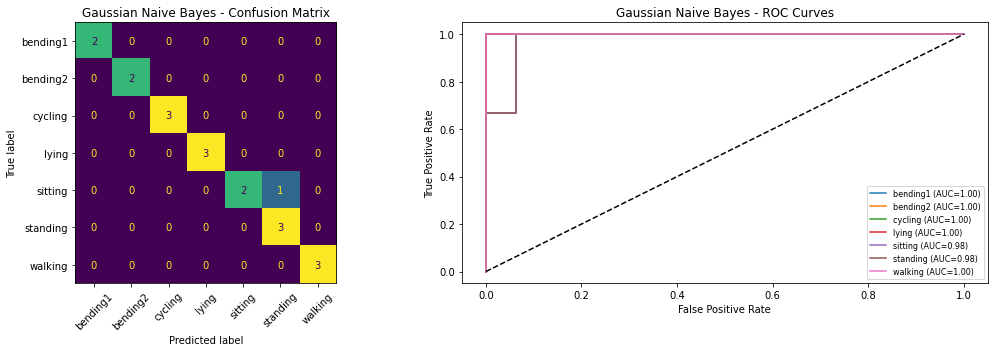


 Multinomial Naive Bayes
Best l: 1
Training Accuracy: 0.8841
Test Accuracy: 0.8421
Test Error: 0.1579
Macro AUC: 0.9762

Test Confusion Matrix:
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 1 2 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]

Classification Report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       0.75      1.00      0.86         3
       lying       0.67      0.67      0.67         3
     sitting       1.00      0.67      0.80         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.87      0.86      0.86        19
weighted avg       0.86      0.84      0.84        19



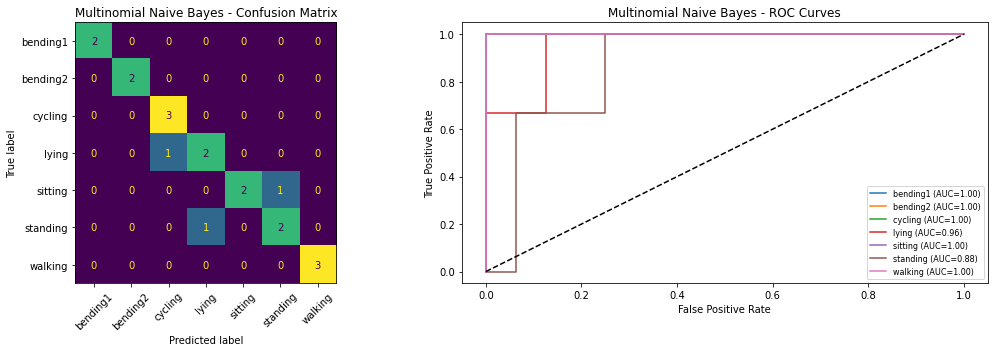


Naive Bayes Comparison:
                  Model  Training Accuracy  Test Accuracy  Test Error  Macro AUC
   Gaussian Naive Bayes             1.0000         0.9474      0.0526     0.9940
Multinomial Naive Bayes             0.8841         0.8421      0.1579     0.9762


In [26]:

# Train and evaluate the two Naive Bayes models

# Gaussian Naive Bayes
gnb_l = int(best_gnb["l"])
gnb_var = float(best_gnb["var_smoothing"])

gnb_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", GaussianNB(var_smoothing=gnb_var))
])

# Multinomial Naive Bayes
mnb_l = int(best_mnb["l"])
mnb_alpha = float(best_mnb["alpha"])

mnb_model = Pipeline([
    ("scaler", MinMaxScaler(clip=True)),
    ("model", MultinomialNB(alpha=mnb_alpha))
])


def evaluate_nb(name, model, l):

    X_train_nb = extract_segment_features(train_data, l)
    X_test_nb = extract_segment_features(test_data, l)

    model.fit(X_train_nb, y_train_multi)

    y_train_pred = model.predict(X_train_nb)
    y_test_pred = model.predict(X_test_nb)
    y_test_prob = model.predict_proba(X_test_nb)

    classes = model.named_steps["model"].classes_

    train_acc = (y_train_pred == y_train_multi).mean()
    test_acc = (y_test_pred == y_test_multi).mean()
    test_error = 1 - test_acc

    macro_auc = roc_auc_score(
        y_test_multi,
        y_test_prob,
        labels=classes,
        multi_class="ovr",
        average="macro"
    )

    print("\n", name)
    print("Best l:", l)
    print("Training Accuracy:", round(train_acc, 4))
    print("Test Accuracy:", round(test_acc, 4))
    print("Test Error:", round(test_error, 4))
    print("Macro AUC:", round(macro_auc, 4))

    print("\nTest Confusion Matrix:")
    print(confusion_matrix(
        y_test_multi,
        y_test_pred,
        labels=classes
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test_multi,
        y_test_pred,
        zero_division=0
    ))

    # Plot confusion matrix and ROC curves
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test_multi,
        y_test_pred,
        labels=classes,
        ax=axes[0],
        colorbar=False,
        xticks_rotation=45
    )

    axes[0].set_title(name + " - Confusion Matrix")

    # One-vs-Rest ROC curves
    y_test_bin = label_binarize(
        y_test_multi,
        classes=classes
    )

    for i, activity in enumerate(classes):

        fpr, tpr, _ = roc_curve(
            y_test_bin[:, i],
            y_test_prob[:, i]
        )

        class_auc = auc(fpr, tpr)

        axes[1].plot(
            fpr,
            tpr,
            label=f"{activity} (AUC={class_auc:.2f})"
        )

    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(name + " - ROC Curves")
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    return {
        "Model": name,
        "Training Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Test Error": test_error,
        "Macro AUC": macro_auc
    }


# Evaluate Gaussian NB
gnb_result = evaluate_nb(
    "Gaussian Naive Bayes",
    gnb_model,
    gnb_l
)

# Evaluate Multinomial NB
mnb_result = evaluate_nb(
    "Multinomial Naive Bayes",
    mnb_model,
    mnb_l
)

# Compare results
nb_comparison = pd.DataFrame([
    gnb_result,
    mnb_result
])

print("\nNaive Bayes Comparison:")
print(nb_comparison.round(4).to_string(index=False))


I used Gaussian Naive Bayes and Multinomial Naive Bayes to classify the seven activities. I used stratified 4-fold cross-validation to select the parameters.

For Gaussian NB, the best l was 2, and the best var_smoothing was 0.01. The CV accuracy was 91.34%, and the test accuracy was 94.74%. Only one sitting activity was incorrectly classified as standing.

For Multinomial NB, the best l was 1, and the best alpha was 0.1. The CV accuracy was 85.62%, and the test accuracy was 84.21%. Three test instances were classified incorrectly.

Gaussian NB performed better than Multinomial NB on this dataset. It had a lower test error and a higher macro AUC.

#### ii. Comparison

From the results, Gaussian Naive Bayes had the highest test accuracy of 94.74%. 
Logistic Regression had a test accuracy of 89.47%.
Multinomial Naive Bayes had 84.21%.

Logistic Regression had a slightly higher CV accuracy than Gaussian NB, but Gaussian NB performed better on the test set.

I think Gaussian NB was the best method for this test set because it had the lowest test error of 5.26%. However, the test set only has 19 instances, so the result may change with more data.

## 3. ISLR 4.8.3


First, we assume X follows a normal distribution as:

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2)
$$

The density function is:

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)
$$

We can use Bayes' theorem:

$$
P(Y=k\mid X=x)\propto \pi_k f_k(x)
$$

Here, $\pi_k$ is the prior probability of class k.

Then we take the log.

After that we remove the constant terms:

$$
\delta_k(x)=\log(\pi_k)-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
$$

We can expand the square:

$$
(x-\mu_k)^2=x^2-2\mu_k x+\mu_k^2
$$

So we get:

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k x}{\sigma_k^2}
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k)
$$

The Bayes classifier chooses the class with the largest value of $\delta_k(x)$.

For the decision boundary between two classes, we set:

$$
\delta_k(x)=\delta_j(x)
$$

From the equation, we can see there is an $x^2$ term. Since QDA allows different variances, the $x^2$ terms do not cancel out when we compare two classes.

So the decision boundary is quadratic.

If the variances are the same, the $x^2$ terms will cancel out, and the boundary becomes linear.

Therefore, QDA has a quadratic decision boundary in general, but LDA has a linear decision boundary.


## 4. ISLR 4.8.7


First, we have two classes: Yes (issue a dividend) and No (not issue a dividend).

From the question, we know:

$$
\mu_{Yes}=10,\quad \mu_{No}=0
$$

$$
\sigma^2=36
$$

$$
P(Yes)=0.8,\quad P(No)=0.2
$$

We want to calculate $P(Yes \mid X=4)$.

Since X follows a normal distribution, we use the density function:

$$
f(x)=\frac{1}{\sqrt{2\pi\sigma^2}}
e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

Then we use Bayes' theorem:

$$
P(Yes \mid X=4)
=
\frac{P(Yes)f_{Yes}(4)}
{P(Yes)f_{Yes}(4)+P(No)f_{No}(4)}
$$

We can substitute the numbers:

$$
P(Yes \mid X=4)
=
\frac{0.8e^{-\frac{(4-10)^2}{2(36)}}}
{0.8e^{-\frac{(4-10)^2}{2(36)}}+
0.2e^{-\frac{(4-0)^2}{2(36)}}}
$$

The common term from the normal density function cancels out.

Then we simplify:

$$
P(Yes \mid X=4)
=
\frac{0.8e^{-0.5}}
{0.8e^{-0.5}+0.2e^{-16/72}}
$$

Finally, we get:

$$
P(Yes \mid X=4)\approx 0.7519=75.19\%
$$

So, the probability that this company will issue a dividend this year is about 75.19%.

Since this probability is greater than 50%, we would predict Yes.


## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9